In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
from dateutil import parser

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.metrics import mean_absolute_error, confusion_matrix, accuracy_score, classification_report, mean_squared_error
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, ExtraTreesRegressor
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.inspection import PartialDependenceDisplay

In [2]:
path = kagglehub.dataset_download("fatihb/coffee-quality-data-cqi")

print("Path to dataset files:", path)

# Load the Kaggle dataset
df = pd.read_csv(path + "/df_arabica_clean.csv")

Path to dataset files: ~\.cache\kagglehub\datasets\fatihb\coffee-quality-data-cqi\versions\1


In [3]:
df.head()

,Unnamed: 0,ID,Country of Origin,Farm Name,Lot Number,Mill,ICO Number,Company,Altitude,Region,...,Total Cup Points,Moisture Percentage,Category One Defects,Quakers,Color,Category Two Defects,Expiration,Certification Body,Certification Address,Certification Contact
0,0,0,Colombia,Finca El Paraiso,CQU2022015,Finca El Paraiso,NaN,Coffee Quality Union,1700-1930,"Piendamo,Cauca",...,89.33,11.8,0,0,green,3,"September 21st, 2023",Japan Coffee Exchange,"〒413-0002 静岡県熱海市伊豆山１１７３−５８ 1173-58 Izusan, Ata...",松澤 宏樹 Koju Matsuzawa - +81(0)9085642901
1,1,1,Taiwan,Royal Bean Geisha Estate,"The 2022 Pacific Rim Coffee Summit,T037",Royal Bean Geisha Estate,NaN,Taiwan Coffee Laboratory,1200,Chiayi,...,87.58,10.5,0,0,blue-green,0,"November 15th, 2023",Taiwan Coffee Laboratory 台灣咖啡研究室,"QAHWAH CO., LTD 4F, No. 225, Sec. 3, Beixin Rd...","Lin, Jen-An Neil 林仁安 - 886-289116612"
2,2,2,Laos,OKLAO coffee farms,"The 2022 Pacific Rim Coffee Summit,LA01",oklao coffee processing plant,NaN,Taiwan Coffee Laboratory,1300,Laos Borofen Plateau,...,87.42,10.4,0,0,yellowish,2,"November 15th, 2023",Taiwan Coffee Laboratory 台灣咖啡研究室,"QAHWAH CO., LTD 4F, No. 225, Sec. 3, Beixin Rd...","Lin, Jen-An Neil 林仁安 - 886-289116612"
3,3,3,Costa Rica,La Cumbre,CQU2022017,La Montana Tarrazu MIll,NaN,Coffee Quality Union,1900,"Los Santos,Tarrazu",...,87.17,11.8,0,0,green,0,"September 21st, 2023",Japan Coffee Exchange,"〒413-0002 静岡県熱海市伊豆山１１７３−５８ 1173-58 Izusan, Ata...",松澤 宏樹 Koju Matsuzawa - +81(0)9085642901
4,4,4,Colombia,Finca Santuario,CQU2023002,Finca Santuario,NaN,Coffee Quality Union,1850-2100,"Popayan,Cauca",...,87.08,11.6,0,2,yellow-green,2,"March 5th, 2024",Japan Coffee Exchange,"〒413-0002 静岡県熱海市伊豆山１１７３−５８ 1173-58 Izusan, Ata...",松澤 宏樹 Koju Matsuzawa - +81(0)9085642901


# Preprocessing, Cleaning and Standardization

In [4]:
# Check for duplicate rows
duplicate_rows_data = df[df.duplicated()]
print("number of duplicate rows: ", duplicate_rows_data.shape)

number of duplicate rows:  (0, 41)


In [5]:
# Count unique values per column
for column in df.columns:
    num_distinct_values = len(df[column].unique())
    print(f"{column}: {num_distinct_values} distinct values")

Unnamed: 0: 207 distinct values
ID: 207 distinct values
Country of Origin: 22 distinct values
Farm Name: 173 distinct values
Lot Number: 188 distinct values
Mill: 163 distinct values
ICO Number: 68 distinct values
Company: 72 distinct values
Altitude: 98 distinct values
Region: 121 distinct values
Producer: 173 distinct values
Number of Bags: 55 distinct values
Bag Weight: 39 distinct values
In-Country Partner: 21 distinct values
Harvest Year: 7 distinct values
Grading Date: 75 distinct values
Owner: 80 distinct values
Variety: 49 distinct values
Status: 1 distinct values
Processing Method: 11 distinct values
Aroma: 19 distinct values
Flavor: 19 distinct values
Aftertaste: 20 distinct values
Acidity: 19 distinct values
Body: 17 distinct values
Balance: 18 distinct values
Uniformity: 3 distinct values
Clean Cup: 1 distinct values
Sweetness: 1 distinct values
Overall: 21 distinct values
Defects: 1 distinct values
Total Cup Points: 81 distinct values
Moisture Percentage: 46 distinct value

In [6]:
# Missing-value ratio per column
data_na = (df.isnull().sum() / len(df)) * 100
data_na = data_na.drop(data_na[data_na == 0].index).sort_values(ascending=False)[:30]
missing_data = pd.DataFrame({'Missing Ratio' :data_na})
missing_data.head(20)

,Missing Ratio
ICO Number,63.768116
Variety,2.898551
Processing Method,2.415459
Mill,1.449275
Farm Name,0.966184
Region,0.966184
Lot Number,0.483092
Altitude,0.483092
Producer,0.483092


In [7]:
# Map processing methods into broader categories
processing_mapping = {
    "Double Anaerobic Washed": "Washed / Wet",
    "Semi Washed": "Washed / Wet",
    "Honey,Mossto": "Pulped natural / honey",
    "Double Carbonic Maceration / Natural": "Natural / Dry",
    "Wet Hulling": "Washed / Wet",
    "Anaerobico 1000h": "Washed / Wet",
    "SEMI-LAVADO": "Natural / Dry"
}

# Apply the mapping
df['Processing Method'] = df['Processing Method'].map(processing_mapping)

# Fill missing values
df['Processing Method'] = df['Processing Method'].fillna("Washed / Wet")


In [8]:
df.head()

,Unnamed: 0,ID,Country of Origin,Farm Name,Lot Number,Mill,ICO Number,Company,Altitude,Region,...,Total Cup Points,Moisture Percentage,Category One Defects,Quakers,Color,Category Two Defects,Expiration,Certification Body,Certification Address,Certification Contact
0,0,0,Colombia,Finca El Paraiso,CQU2022015,Finca El Paraiso,NaN,Coffee Quality Union,1700-1930,"Piendamo,Cauca",...,89.33,11.8,0,0,green,3,"September 21st, 2023",Japan Coffee Exchange,"〒413-0002 静岡県熱海市伊豆山１１７３−５８ 1173-58 Izusan, Ata...",松澤 宏樹 Koju Matsuzawa - +81(0)9085642901
1,1,1,Taiwan,Royal Bean Geisha Estate,"The 2022 Pacific Rim Coffee Summit,T037",Royal Bean Geisha Estate,NaN,Taiwan Coffee Laboratory,1200,Chiayi,...,87.58,10.5,0,0,blue-green,0,"November 15th, 2023",Taiwan Coffee Laboratory 台灣咖啡研究室,"QAHWAH CO., LTD 4F, No. 225, Sec. 3, Beixin Rd...","Lin, Jen-An Neil 林仁安 - 886-289116612"
2,2,2,Laos,OKLAO coffee farms,"The 2022 Pacific Rim Coffee Summit,LA01",oklao coffee processing plant,NaN,Taiwan Coffee Laboratory,1300,Laos Borofen Plateau,...,87.42,10.4,0,0,yellowish,2,"November 15th, 2023",Taiwan Coffee Laboratory 台灣咖啡研究室,"QAHWAH CO., LTD 4F, No. 225, Sec. 3, Beixin Rd...","Lin, Jen-An Neil 林仁安 - 886-289116612"
3,3,3,Costa Rica,La Cumbre,CQU2022017,La Montana Tarrazu MIll,NaN,Coffee Quality Union,1900,"Los Santos,Tarrazu",...,87.17,11.8,0,0,green,0,"September 21st, 2023",Japan Coffee Exchange,"〒413-0002 静岡県熱海市伊豆山１１７３−５８ 1173-58 Izusan, Ata...",松澤 宏樹 Koju Matsuzawa - +81(0)9085642901
4,4,4,Colombia,Finca Santuario,CQU2023002,Finca Santuario,NaN,Coffee Quality Union,1850-2100,"Popayan,Cauca",...,87.08,11.6,0,2,yellow-green,2,"March 5th, 2024",Japan Coffee Exchange,"〒413-0002 静岡県熱海市伊豆山１１７３−５８ 1173-58 Izusan, Ata...",松澤 宏樹 Koju Matsuzawa - +81(0)9085642901


In [9]:
print(df.loc[df['ID'].isin([99, 105, 180]), ['ID', 'Altitude']])

      ID     Altitude
99    99  4895 A 5650
105  105          NaN
180  180    1200~1600


In [10]:
df[df.columns[df.isnull().any()]].isnull().sum()

Farm Name       2
Lot Number      1
Mill            3
ICO Number    132
Altitude        1
Region          2
Producer        1
Variety         6
dtype: int64

In [11]:
# Detect malformed values with a regex
weird_altitudes = df[df['Altitude'].astype(str).str.contains(r'[^\d\.]', regex=True)]
print(weird_altitudes[['Altitude']])

        Altitude
0      1700-1930
4      1850-2100
9      1400-1700
10     1800-2200
13     1900-2000
16     1900-2100
19     1570-1600
22     1500-1700
30       150-250
31       150-250
34   2150 - 2350
38     1600-1900
40       300-500
49       350-400
62       200-300
74     1300-1400
79     1250-1350
86     1500-1600
87     1500-1600
89     1600-1750
91     1400-1700
92     1400-1700
96     1300-1400
99   4895 A 5650
102      400-600
105          NaN
108      200-400
110      250-400
111      250-300
115  1200 - 1580
118  1400 - 1900
121      200-300
122    1280-1325
127    1300-1500
128    1400-1700
130    1100-1200
134      200-300
136  1200 - 1300
140      250-300
145    1300-1500
150  1200 - 1580
163    1200-1350
170    1500-1950
175     800-1200
177    1350-1550
180    1200~1600
184     900-1000
190    1300-1500
192      600-800
193    1300-1800
206     850-1100


In [12]:
df.loc[df['ID'] == 99, 'Altitude'] = 5273  # Impute value for ID 99
df.loc[df['ID'] == 105, 'Altitude'] = 1800  # Impute value for ID 105
df.loc[df['ID'] == 180, 'Altitude'] = 1400  # Impute value for ID 180

def clean_altitude_range(range_value):
    if isinstance(range_value, str):  # Check whether the value is a string
        range_value = range_value.replace(" ", "")  # Remove whitespace

        if '-' in range_value:  # If the value is a range (e.g. "1500-1800")
            try:
                start, end = range_value.split('-')  # Split the range into two values
                start = int(start)  # Convert to integers
                end = int(end)
                return (start + end) / 2  # Return the midpoint
            except ValueError:
                return np.nan  # Return NaN if the conversion fails

        else:  # Not a range: try converting to an integer
            try:
                return int(range_value)
            except ValueError:
                return np.nan  # Return NaN if the conversion fails

    else:  # Non-string values are returned unchanged
        return range_value

In [13]:

df['Altitude'] = df['Altitude'].apply(clean_altitude_range)

# Re-apply the manual fixes for the malformed entries
df.loc[df['ID'] == 99, 'Altitude'] = 5273
df.loc[df['ID'] == 105, 'Altitude'] = 1800
df.loc[df['ID'] == 180, 'Altitude'] = 1400

print("Missing values before imputation:", df['Altitude'].isna().sum())

imputer = SimpleImputer(strategy='mean')
altitude_imputed = imputer.fit_transform(df[['Altitude']])
df['Altitude'] = altitude_imputed

print("Missing values after imputation:", df['Altitude'].isna().sum())


Missing values before imputation: 0
Missing values after imputation: 0


In [14]:
# Extract the prior year from the "Harvest Year" column
df['Harvest Year'] = df['Harvest Year'].str.split('/').str[0].str.strip()

In [15]:
# Convert "Harvest Year" and "Expiration" columns to datetime objects using dateutil parser
df['Harvest Year'] = pd.to_datetime(df['Harvest Year'], format='%Y')
df['Expiration'] = df['Expiration'].apply(parser.parse)

In [16]:
# Calculate the difference in days between "Expiration" and "Harvest Year" columns
df['Coffee Age'] = (df['Expiration'] - df['Harvest Year']).dt.days

In [17]:
# Drop columns that add no value (mostly empty or irrelevant)
columns_to_drop = ['ID','ICO Number','Owner','Region','Certification Contact','Certification Address','Farm Name',"Lot Number","Mill","ICO Number","Producer",'Company','Expiration', 'Harvest Year', "Unnamed: 0",'Number of Bags','Bag Weight','In-Country Partner','Grading Date','Variety','Status','Defects','Uniformity','Clean Cup','Sweetness','Certification Body']
df.drop(columns_to_drop, axis=1, inplace=True)

In [18]:
df.head()

,Country of Origin,Altitude,Processing Method,Aroma,Flavor,Aftertaste,Acidity,Body,Balance,Overall,Total Cup Points,Moisture Percentage,Category One Defects,Quakers,Color,Category Two Defects,Coffee Age
0,Colombia,1815.0,Washed / Wet,8.58,8.50,8.42,8.58,8.25,8.42,8.58,89.33,11.8,0,0,green,3,993
1,Taiwan,1200.0,Washed / Wet,8.50,8.50,7.92,8.00,7.92,8.25,8.50,87.58,10.5,0,0,blue-green,0,1048
2,Laos,1300.0,Washed / Wet,8.33,8.42,8.08,8.17,7.92,8.17,8.33,87.42,10.4,0,0,yellowish,2,1048
3,Costa Rica,1900.0,Washed / Wet,8.08,8.17,8.17,8.25,8.17,8.08,8.25,87.17,11.8,0,0,green,0,628
4,Colombia,1975.0,Pulped natural / honey,8.33,8.33,8.08,8.25,7.92,7.92,8.25,87.08,11.6,0,2,yellow-green,2,794


# **Exploratory Analysis**

In [19]:
df.shape
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 207 entries, 0 to 206
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Country of Origin     207 non-null    object 
 1   Altitude              207 non-null    float64
 2   Processing Method     207 non-null    object 
 3   Aroma                 207 non-null    float64
 4   Flavor                207 non-null    float64
 5   Aftertaste            207 non-null    float64
 6   Acidity               207 non-null    float64
 7   Body                  207 non-null    float64
 8   Balance               207 non-null    float64
 9   Overall               207 non-null    float64
 10  Total Cup Points      207 non-null    float64
 11  Moisture Percentage   207 non-null    float64
 12  Category One Defects  207 non-null    int64  
 13  Quakers               207 non-null    int64  
 14  Color                 207 non-null    object 
 15  Category Two Defects  2

In [20]:
df.describe()

,Altitude,Aroma,Flavor,Aftertaste,Acidity,Body,Balance,Overall,Total Cup Points,Moisture Percentage,Category One Defects,Quakers,Category Two Defects,Coffee Age
count,207.000000,207.000000,207.000000,207.000000,207.00000,207.000000,207.000000,207.000000,207.000000,207.000000,207.000000,207.000000,207.000000,207.000000
mean,1314.099034,7.721063,7.744734,7.599758,7.69029,7.640918,7.644058,7.676812,83.706570,10.735266,0.135266,0.690821,2.251208,893.565217
std,720.564046,0.287626,0.279613,0.275911,0.25951,0.233499,0.256299,0.306359,1.730417,1.247468,0.592070,1.686918,2.950183,234.373891
min,139.000000,6.500000,6.750000,6.670000,6.83000,6.830000,6.670000,6.670000,78.000000,0.000000,0.000000,0.000000,0.000000,431.000000
25%,1020.000000,7.580000,7.580000,7.420000,7.50000,7.500000,7.500000,7.500000,82.580000,10.100000,0.000000,0.000000,0.000000,753.000000
50%,1340.000000,7.670000,7.750000,7.580000,7.67000,7.670000,7.670000,7.670000,83.750000,10.800000,0.000000,0.000000,1.000000,880.000000
75%,1600.000000,7.920000,7.920000,7.750000,7.87500,7.750000,7.790000,7.920000,84.830000,11.500000,0.000000,1.000000,3.000000,1048.000000
max,5400.000000,8.580000,8.500000,8.420000,8.58000,8.250000,8.420000,8.580000,89.330000,13.500000,5.000000,12.000000,16.000000,2487.000000


In [21]:
num_columns = df.select_dtypes(include=['number']).columns.tolist()
print(num_columns)

['Altitude', 'Aroma', 'Flavor', 'Aftertaste', 'Acidity', 'Body', 'Balance', 'Overall', 'Total Cup Points', 'Moisture Percentage', 'Category One Defects', 'Quakers', 'Category Two Defects', 'Coffee Age']


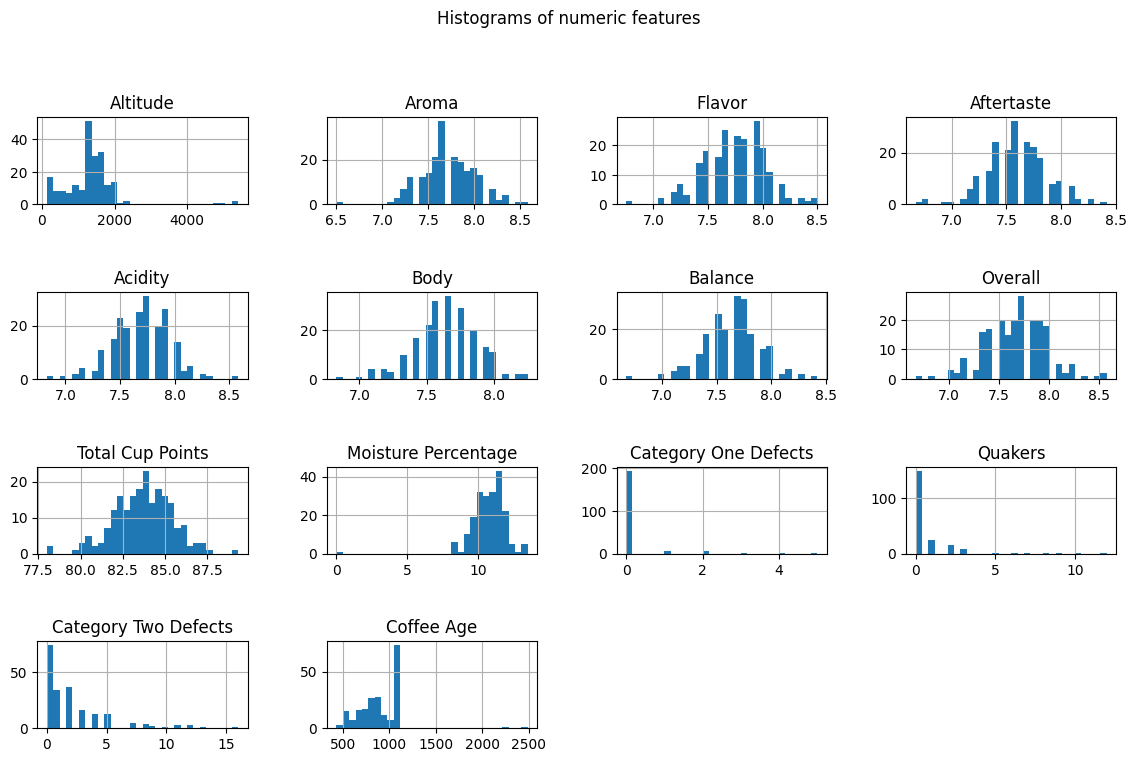

In [22]:
df[num_columns].hist(figsize=(12, 8), bins=30)
plt.suptitle('Histograms of numeric features')
plt.tight_layout(pad=3)
plt.show()

In [23]:
cat_columns = df.select_dtypes(include=['object']).columns.tolist()
print(cat_columns)

['Country of Origin', 'Processing Method', 'Color']


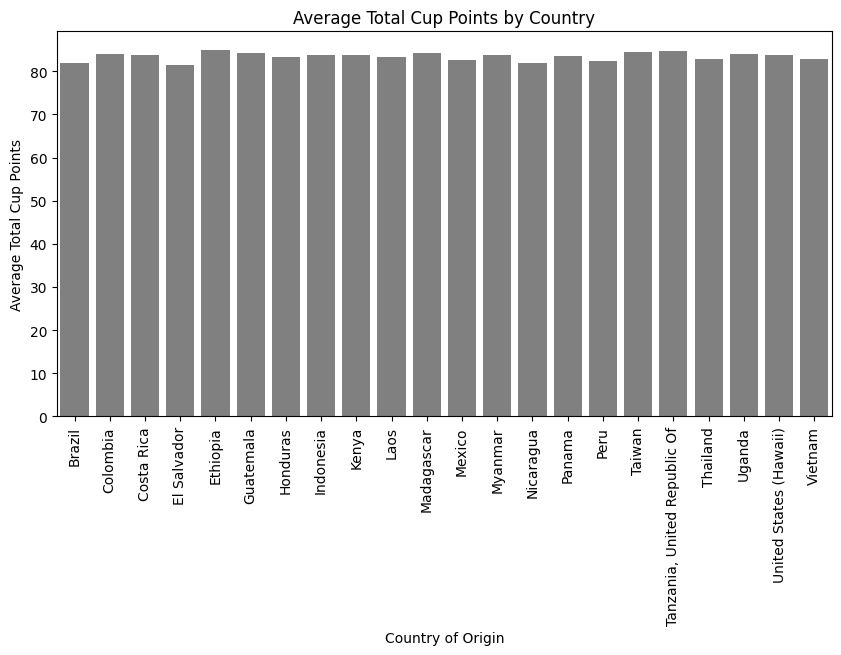

In [24]:
# Create a bar plot with gray color

df_grouped = df.groupby('Country of Origin')['Total Cup Points'].mean().reset_index()

plt.figure(figsize=(10, 5))
sns.barplot(x=df_grouped['Country of Origin'], y=df_grouped['Total Cup Points'], color='gray')
plt.title('Average Total Cup Points by Country')
plt.xlabel('Country of Origin')
plt.ylabel('Average Total Cup Points')
plt.xticks(rotation=90)
plt.show()

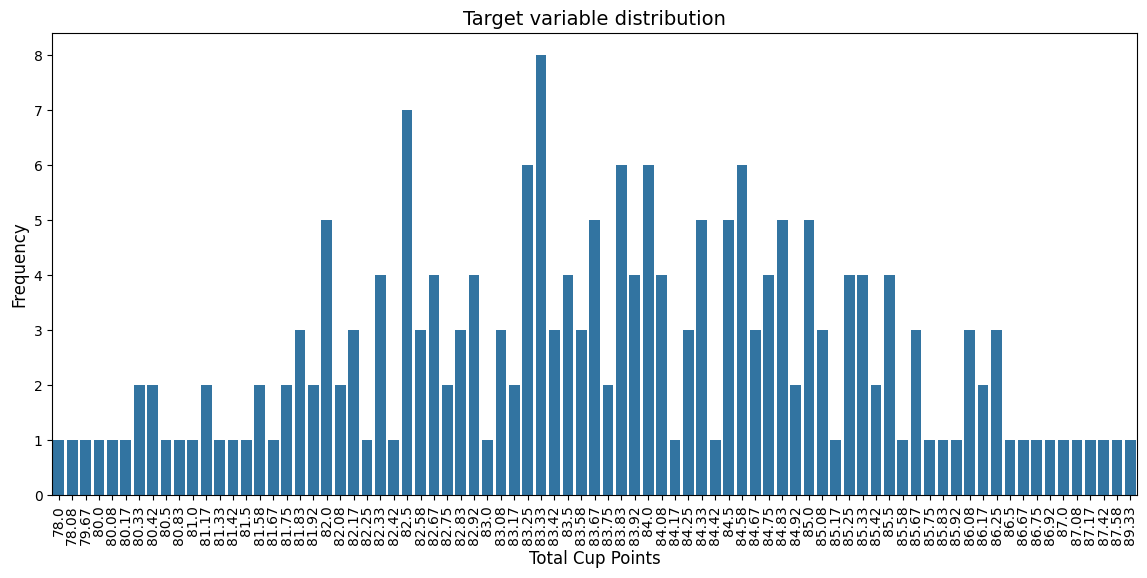

In [25]:
plt.figure(figsize=(14, 6))
sns.countplot(x=df['Total Cup Points'])
plt.title('Target variable distribution', fontsize=14)
plt.xticks(rotation=90, fontsize=10)
plt.xlabel('Total Cup Points', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.show()


In [26]:
df['Altitude'] = pd.to_numeric(df['Altitude'], errors='coerce')
print(df[['Altitude', 'Total Cup Points']].dtypes)

Altitude            float64
Total Cup Points    float64
dtype: object


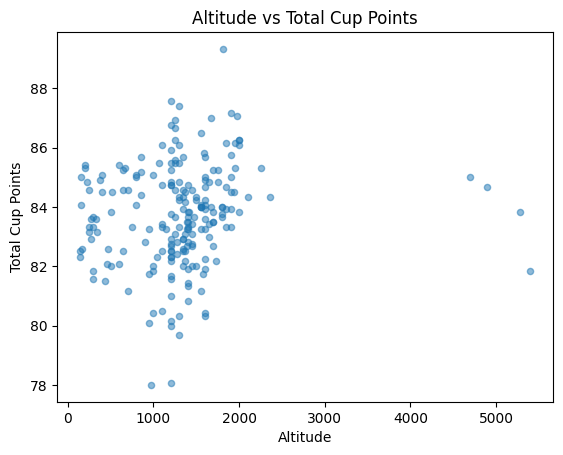

In [27]:
df.plot.scatter(x='Altitude', y='Total Cup Points', alpha=0.5)
plt.title("Altitude vs Total Cup Points")
plt.show()

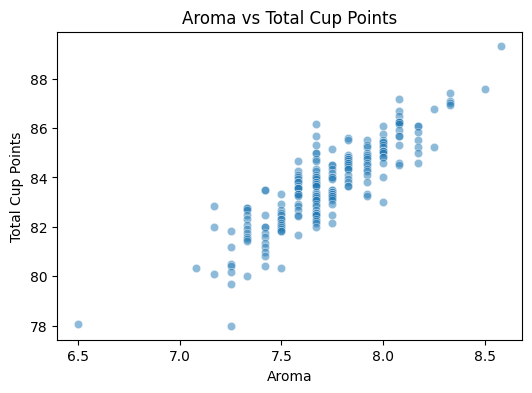

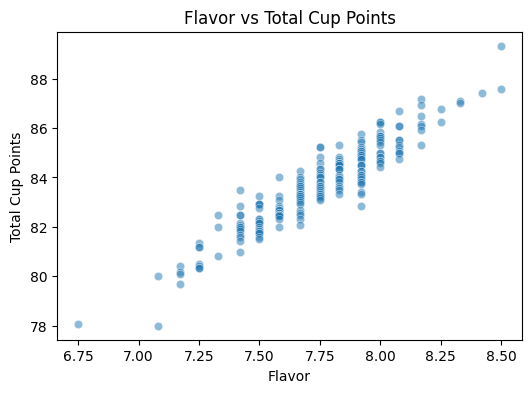

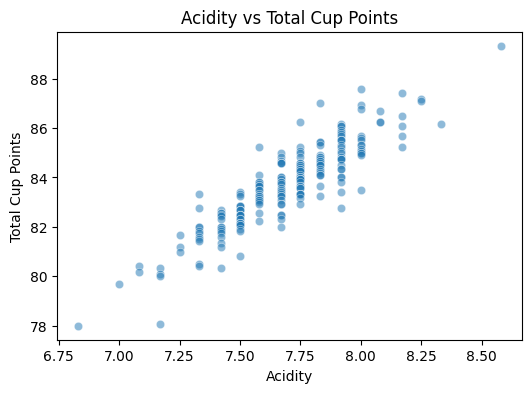

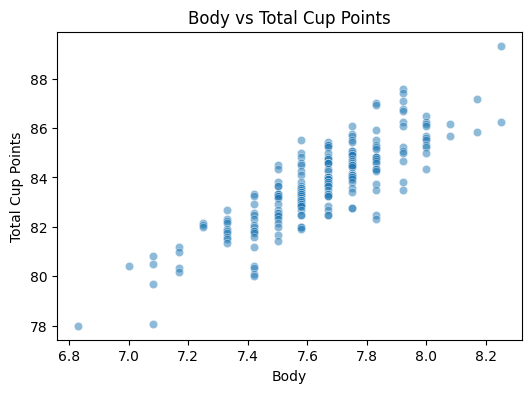

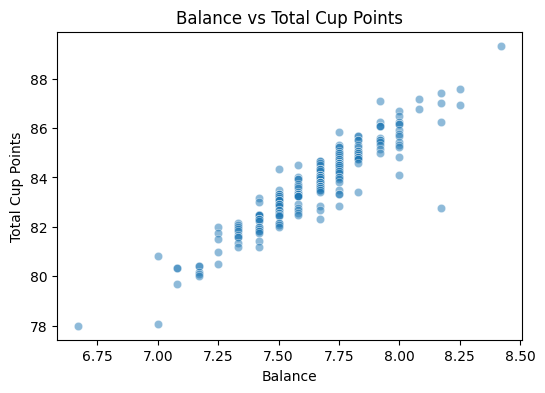

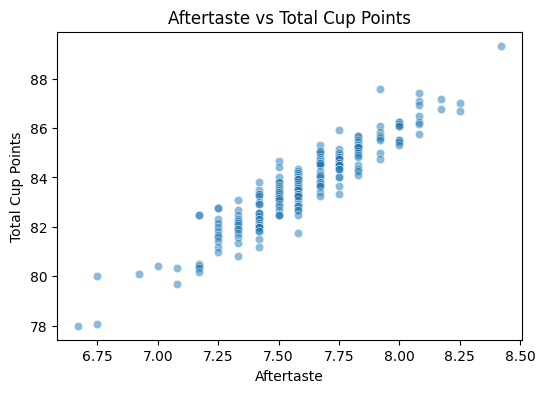

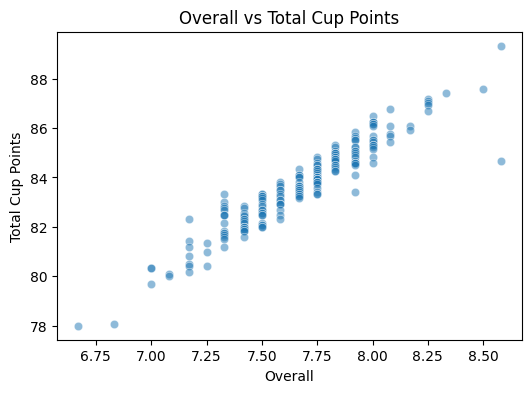

In [28]:
sensorial_features = ['Aroma', 'Flavor', 'Acidity', 'Body', 'Balance', 'Aftertaste', 'Overall']

for feature in sensorial_features:
    plt.figure(figsize=(6, 4))
    sns.scatterplot(x=df[feature], y=df['Total Cup Points'], alpha=0.5)
    plt.title(f'{feature} vs Total Cup Points')
    plt.show()


# Encoding and Normalization

In [29]:
data = df.copy()
categorical_columns = ['Processing Method']
numerical_columns = ['Altitude', 'Aroma', 'Flavor', 'Aftertaste', 'Acidity', 'Body', 'Balance', 'Overall', 'Total Cup Points', 'Moisture Percentage', 'Category One Defects', 'Quakers', 'Category Two Defects', 'Coffee Age']
columns_to_drop = ['Country of Origin', 'Color']
data.drop(columns_to_drop, axis=1, inplace=True)

In [30]:
dummy_variables = pd.get_dummies(data, columns=categorical_columns, drop_first=False)

In [31]:
# One-hot encode the categorical features
data_encoded = pd.get_dummies(data, columns=categorical_columns, drop_first=False)

In [32]:
# Standardize the numeric features
scaler = StandardScaler()
scaled_numerical = scaler.fit_transform(data[numerical_columns])
scaled_numerical_df = pd.DataFrame(scaled_numerical, columns=numerical_columns)

In [33]:
# Drop the original (unscaled) numeric columns from data_encoded
data_encoded = data_encoded.drop(columns=numerical_columns, axis=1)

# Combine the encoded and scaled features
processed_df = pd.concat([data_encoded, scaled_numerical_df], axis=1)

In [34]:
# Full correlation matrix
correlation_matrix = processed_df.corr()

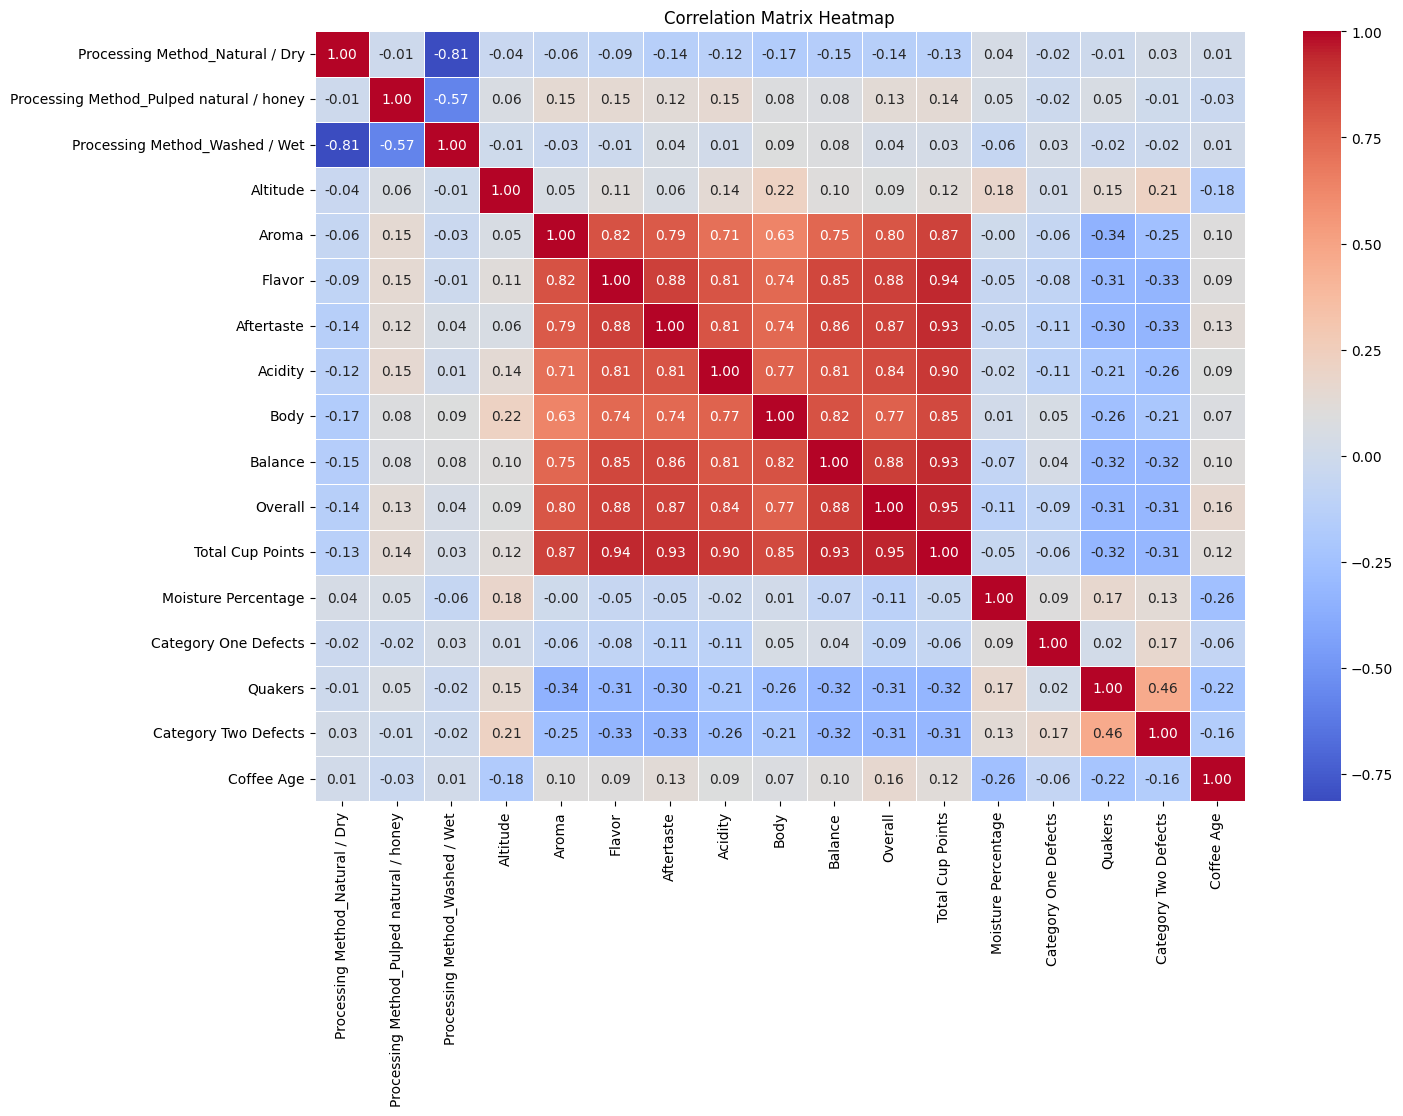

In [35]:
plt.figure(figsize=(15, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', linewidths=0.5, fmt='.2f')
plt.title("Correlation Matrix Heatmap")
plt.show()

In [36]:
# Correlation with the target
target_corr = correlation_matrix['Total Cup Points'].drop('Total Cup Points')
target_corr_sorted = target_corr.sort_values(ascending=False)

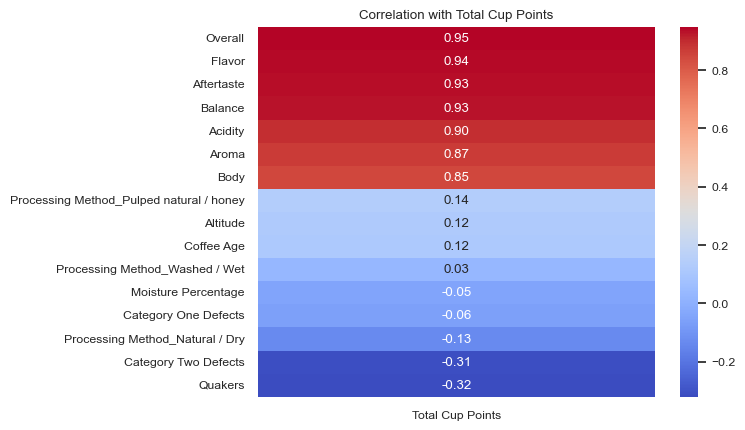

In [37]:
# Plot: correlation with the target only
sns.set(font_scale=0.8)
sns.set_style("white")
sns.heatmap(target_corr_sorted.to_frame(), cmap="coolwarm", annot=True, fmt='.2f')
plt.title('Correlation with Total Cup Points')
plt.show()

# Train/Test Split and Training

In [38]:
X = processed_df.drop(columns=['Total Cup Points'])
y = processed_df['Total Cup Points']

In [39]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

Models and pipelines

In [40]:
rf_base = RandomForestRegressor(random_state=42)
gb_base = GradientBoostingRegressor(random_state=42)
et_base = ExtraTreesRegressor(random_state=42)

pipeline_rf = Pipeline([('regressor', rf_base)])
pipeline_gb = Pipeline([('regressor', gb_base)])
pipeline_et = Pipeline([('regressor', et_base)])

Hyperparameter grid for the grid search

In [41]:
param_grid = {
    'regressor__n_estimators': [100, 200],
    'regressor__max_depth': [5, 10, None],
    'regressor__min_samples_split': [2, 10],
    'regressor__min_samples_leaf': [1, 4]
}

rf = GridSearchCV(pipeline_rf, param_grid=param_grid, cv=3, n_jobs=-1)
gb = GridSearchCV(pipeline_gb, param_grid=param_grid, cv=3, n_jobs=-1)
et = GridSearchCV(pipeline_et, param_grid=param_grid, cv=3, n_jobs=-1)

Training

In [42]:
rf.fit(X_train, y_train) # Random Forest
gb.fit(X_train, y_train) # Gradient Boosting
et.fit(X_train, y_train) # Extra Trees

,estimator,Pipeline(step...m_state=42))])
,param_grid,"{'regressor__max_depth': [5, 10, ...], 'regressor__min_samples_leaf': [1, 4], 'regressor__min_samples_split': [2, 10], 'regressor__n_estimators': [100, 200]}"
,scoring,None
,n_jobs,-1
,refit,True
,cv,3
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,200


# Results Evaluation

In [43]:
models = {'Random Forest': rf, 'Gradient Boosting': gb, 'Extra Trees': et}

print("Train set")
for name, model in models.items():
    print(f"Model: {name}")
    print(f'R^2: {model.score(X_train, y_train)}')
    print(f'MAE: {mean_absolute_error(y_train, model.predict(X_train))}')
    print('\n')

print("Test set")
for name, model in models.items():
    print(f"Model: {name}")
    print(f'R^2: {model.score(X_test, y_test)}')
    print(f'MAE: {mean_absolute_error(y_test, model.predict(X_test))}')
    print('\n')

Train set
Model: Random Forest
R^2: 0.9940605238693389
MAE: 0.049335015020986986


Model: Gradient Boosting
R^2: 0.9999983672687793
MAE: 0.000980291032908768


Model: Extra Trees
R^2: 0.999951687827234
MAE: 0.0042773058232726795


Test set
Model: Random Forest
R^2: 0.9468443984638673
MAE: 0.12631438987114613


Model: Gradient Boosting
R^2: 0.955407170371647
MAE: 0.11365366733203806


Model: Extra Trees
R^2: 0.9659401765167948
MAE: 0.08118170311846871




In [44]:
print("Best mean cross-validation R²:")
print(f"Random Forest: {rf.best_score_:.4f}")
print(f"Gradient Boosting: {gb.best_score_:.4f}")
print(f"Extra Trees: {et.best_score_:.4f}")

Best mean cross-validation R²:
Random Forest: 0.9602
Gradient Boosting: 0.9650
Extra Trees: 0.9687


# Predictions

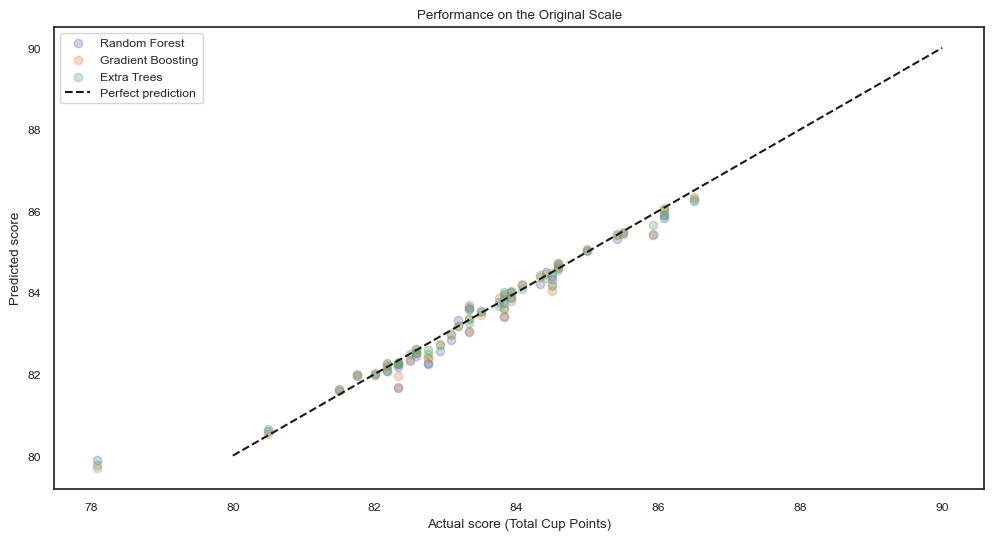


MAE in actual points:
- Random Forest: 0.22
- Gradient Boosting: 0.20
- Extra Trees: 0.14

R²:
- Random Forest: 0.95
- Gradient Boosting: 0.96
- Extra Trees: 0.97


In [45]:
# Predictions (on the standardized scale)
y_pred_rf = rf.predict(X_test)  # Random Forest
y_pred_gb = gb.predict(X_test)  # Gradient Boosting
y_pred_et = et.predict(X_test)  # Extra Trees

# Convert back to the original scale
mean = scaler.mean_[numerical_columns.index('Total Cup Points')]
std = scaler.scale_[numerical_columns.index('Total Cup Points')]

y_test_real = (y_test * std) + mean
y_pred_rf_real = (y_pred_rf * std) + mean
y_pred_gb_real = (y_pred_gb * std) + mean
y_pred_et_real = (y_pred_et * std) + mean

# Comparison plot (original scale)
plt.figure(figsize=(12, 6))
plt.scatter(y_test_real, y_pred_rf_real, alpha=0.3, label='Random Forest')
plt.scatter(y_test_real, y_pred_gb_real, alpha=0.3, label='Gradient Boosting')
plt.scatter(y_test_real, y_pred_et_real, alpha=0.3, label='Extra Trees')
plt.plot([80, 90], [80, 90], 'k--', label='Perfect prediction')  # Typical score range
plt.xlabel("Actual score (Total Cup Points)")
plt.ylabel("Predicted score")
plt.title("Performance on the Original Scale")
plt.legend()
plt.show()

# Metrics on the original scale
from sklearn.metrics import mean_absolute_error, r2_score

print("\nMAE in actual points:")
print(f"- Random Forest: {mean_absolute_error(y_test_real, y_pred_rf_real):.2f}")
print(f"- Gradient Boosting: {mean_absolute_error(y_test_real, y_pred_gb_real):.2f}")
print(f"- Extra Trees: {mean_absolute_error(y_test_real, y_pred_et_real):.2f}")

print("\nR²:")
print(f"- Random Forest: {r2_score(y_test_real, y_pred_rf_real):.2f}")
print(f"- Gradient Boosting: {r2_score(y_test_real, y_pred_gb_real):.2f}")
print(f"- Extra Trees: {r2_score(y_test_real, y_pred_et_real):.2f}")

# Explainability

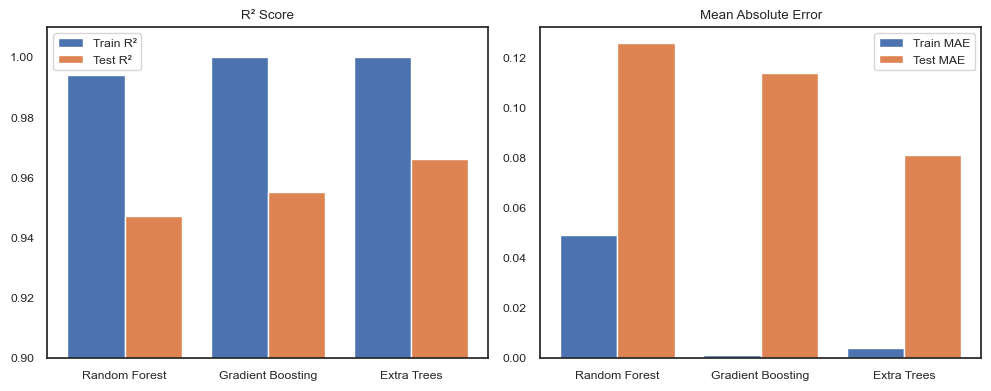

In [46]:
models = ['Random Forest', 'Gradient Boosting', 'Extra Trees']
r2_train = [0.994, 0.999998, 0.99995]
r2_test = [0.947, 0.955, 0.966]
mae_train = [0.049, 0.001, 0.004]
mae_test = [0.126, 0.114, 0.081]

x = np.arange(len(models))

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.bar(x - 0.2, r2_train, 0.4, label='Train R²')
plt.bar(x + 0.2, r2_test, 0.4, label='Test R²')
plt.xticks(x, models)
plt.ylim(0.9, 1.01)
plt.title('R² Score')
plt.legend()

plt.subplot(1, 2, 2)
plt.bar(x - 0.2, mae_train, 0.4, label='Train MAE')
plt.bar(x + 0.2, mae_test, 0.4, label='Test MAE')
plt.xticks(x, models)
plt.title('Mean Absolute Error')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
!pip install shap

In [48]:
import shap
from IPython.display import HTML

In [49]:
# Refit each pipeline with the best parameters found by cross-validation
pipeline_rf.set_params(**rf.best_params_)
pipeline_rf.fit(X_train, y_train)

pipeline_gb.set_params(**gb.best_params_)
pipeline_gb.fit(X_train, y_train)

pipeline_et.set_params(**et.best_params_)
pipeline_et.fit(X_train, y_train)

,steps,"[('regressor', ...)]"
,transform_input,None
,memory,None
,verbose,False
,n_estimators,200
,criterion,'squared_error'
,max_depth,10
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0


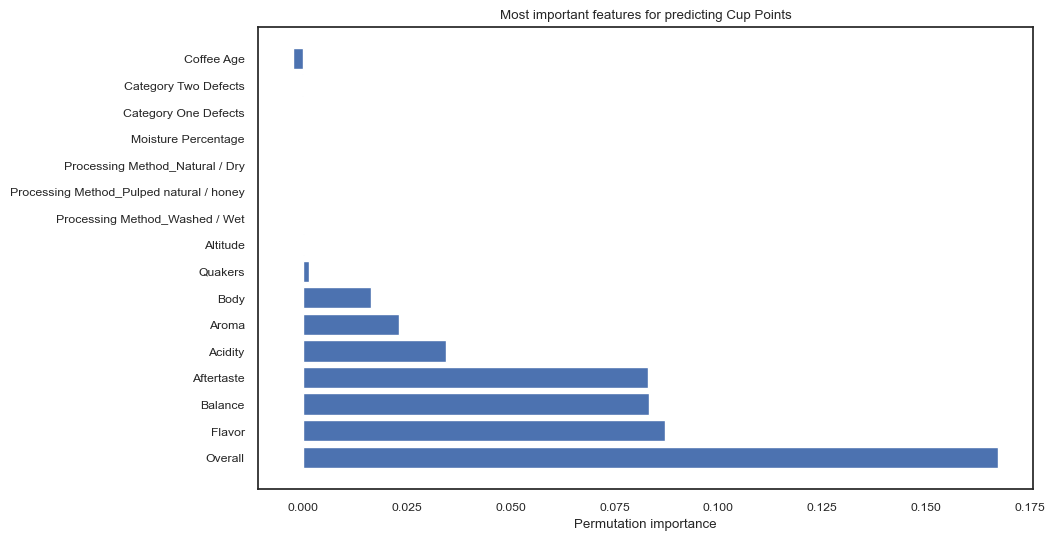

In [50]:
from sklearn.inspection import permutation_importance

# Permutation importance for the tuned Extra Trees model
result = permutation_importance(et, X_test, y_test, n_repeats=10, random_state=42)

# Sort importances
sorted_idx = result.importances_mean.argsort()[::-1]

# Plot
plt.figure(figsize=(10, 6))
plt.barh(X.columns[sorted_idx], result.importances_mean[sorted_idx])
plt.xlabel("Permutation importance")
plt.title("Most important features for predicting Cup Points")
plt.show()

In [51]:
# Build a SHAP explainer for each model
rf_explainer = shap.TreeExplainer(pipeline_rf.named_steps["regressor"])
test_rf_shap_values = rf_explainer.shap_values(X_test)

gb_explainer = shap.TreeExplainer(pipeline_gb.named_steps["regressor"])
test_gb_shap_values = gb_explainer.shap_values(X_test)

et_explainer = shap.TreeExplainer(pipeline_et.named_steps["regressor"])
test_et_shap_values = et_explainer.shap_values(X_test)

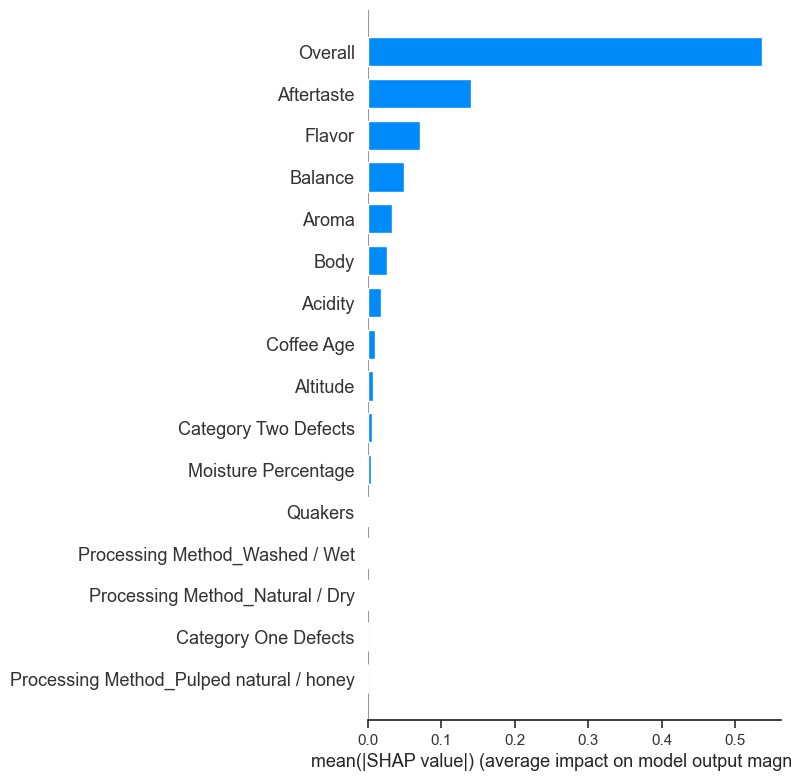

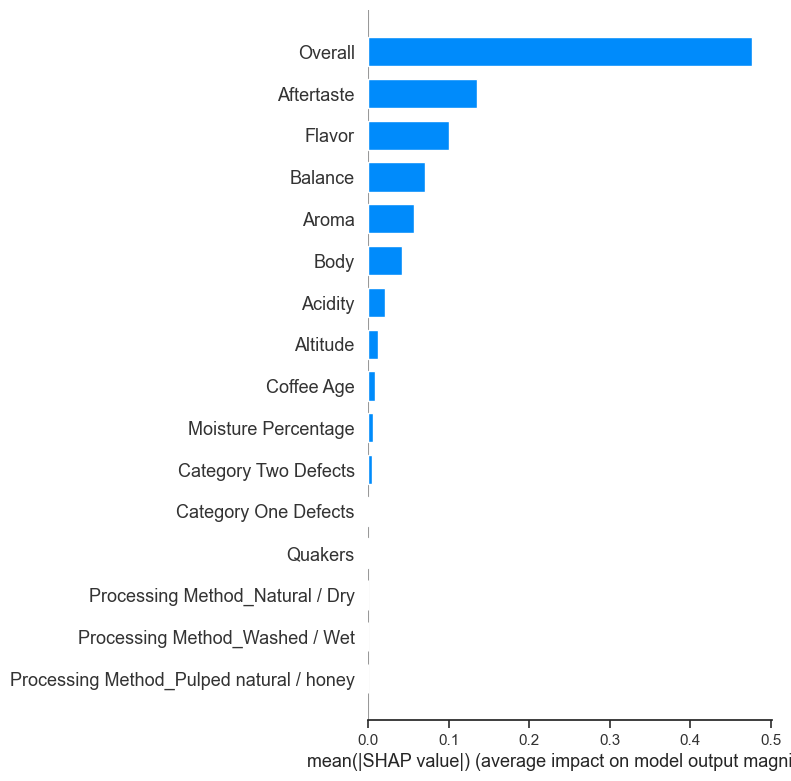

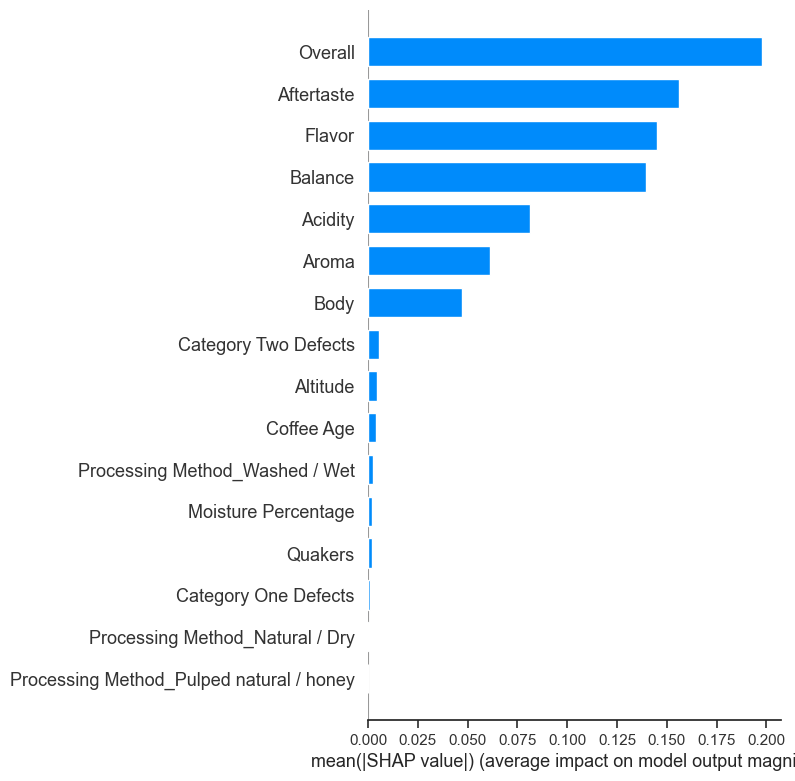

In [52]:
# Summary plot
shap.summary_plot(test_rf_shap_values, X_test, plot_type="bar") # Random Forest
shap.summary_plot(test_gb_shap_values, X_test, plot_type="bar") # Gradient Boosting
shap.summary_plot(test_et_shap_values, X_test, plot_type="bar") # Extra Trees

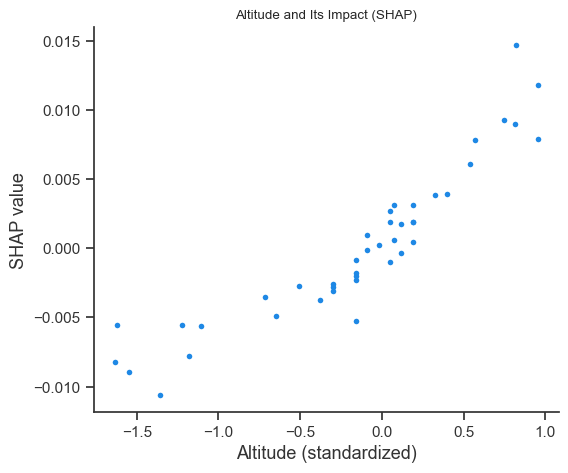

In [53]:
altitude_idx = list(X_test.columns).index("Altitude")
shap.dependence_plot(
    ind=altitude_idx,                      # Index of "Altitude"
    shap_values=test_et_shap_values,       # SHAP values
    features=X_test,                       # Test data
    feature_names=X_test.columns,          # Feature names
    interaction_index=None,                # No interaction
    show=False
)
plt.title("Altitude and Its Impact (SHAP)")
plt.xlabel("Altitude (standardized)")
plt.ylabel("SHAP value")
plt.show()

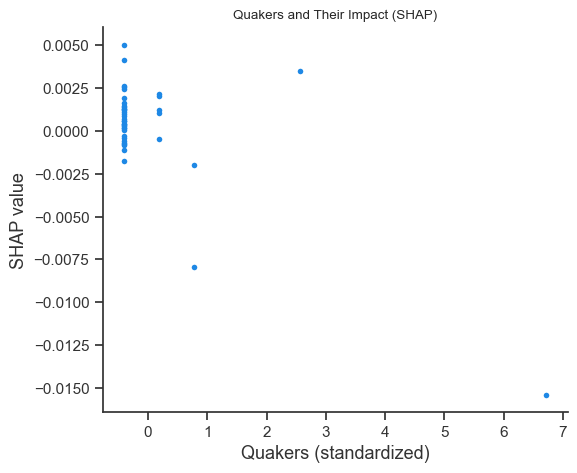

In [54]:
quakers_idx = list(X_test.columns).index("Quakers")
shap.dependence_plot(
    ind=quakers_idx,                      # Index of "Quakers"
    shap_values=test_et_shap_values,       # SHAP values
    features=X_test,                       # Test data
    feature_names=X_test.columns,          # Feature names
    interaction_index=None,                # No interaction
    show=False
)
plt.title("Quakers and Their Impact (SHAP)")
plt.xlabel("Quakers (standardized)")
plt.ylabel("SHAP value")
plt.show()

=== Quality Predictions ===


,Aroma,Flavor,Overall,Predicted Total Cup Points
0,7.580000,7.580000,7.500000,82.490000
1,8.170000,8.080000,8.000000,86.030000
2,8.440000,8.500000,8.560000,88.830000


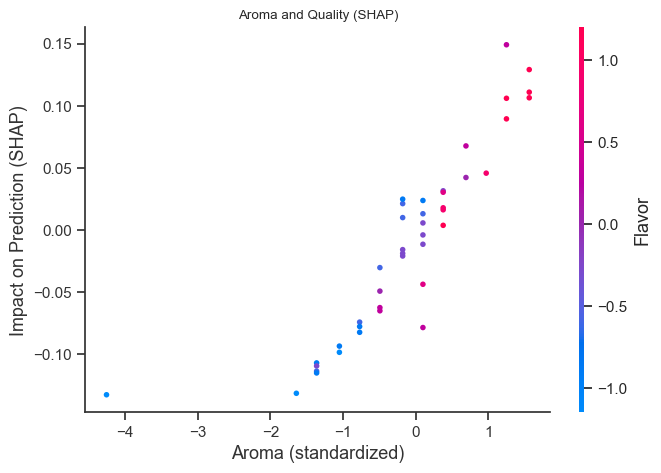

In [55]:

from IPython.display import display

demo_data = pd.DataFrame({
    "Processing Method_Natural / Dry": [False, False, False],
    "Processing Method_Pulped natural / honey": [False, True, False],
    "Processing Method_Washed / Wet": [True, False, True],
    "Altitude": [0.07, -0.29, 1.20],
    "Aroma": [-0.49, 1.56, 2.50],
    "Flavor": [-0.59, 1.20, 2.70],
    "Aftertaste": [-0.98, 1.45, 2.90],
    "Acidity": [-0.73, 0.88, 3.40],
    "Body": [-0.26, 1.54, 2.60],
    "Balance": [-0.87, 1.07, 3.00],
    "Overall": [-0.57, 1.05, 2.90],
    "Moisture Percentage": [-0.10, -0.43, 0.85],
    "Category One Defects": [-0.22, -0.22, -0.22],
    "Quakers": [-0.41, -0.41, 0.77],
    "Category Two Defects": [1.95, -0.76, -0.08],
    "Coffee Age": [-0.09, 0.66, -1.13]
})

predictions = pipeline_et.predict(demo_data)

# The inputs and predictions are standardized: convert them back to the original scale
def to_original_scale(values, column):
    idx = numerical_columns.index(column)
    return values * scaler.scale_[idx] + scaler.mean_[idx]

demo_results = pd.DataFrame({
    col: to_original_scale(demo_data[col], col).round(2) for col in ["Aroma", "Flavor", "Overall"]
})
demo_results["Predicted Total Cup Points"] = to_original_scale(predictions, "Total Cup Points").round(2)

print("=== Quality Predictions ===")
display(demo_results.style
      .background_gradient(cmap="RdYlGn", subset=["Predicted Total Cup Points"]))


shap.dependence_plot(
    "Aroma",
    test_et_shap_values,
    X_test,
    interaction_index="Flavor",
    show=False
)
plt.title("Aroma and Quality (SHAP)")
plt.xlabel("Aroma (standardized)")
plt.ylabel("Impact on Prediction (SHAP)")
plt.show()

In [56]:
from ipywidgets import interact, FloatSlider

# Use the fitted scaler so inputs and predictions are converted with the real
# means and standard deviations of the training data
target_idx = numerical_columns.index('Total Cup Points')
target_mean, target_std = scaler.mean_[target_idx], scaler.scale_[target_idx]

# Features without a slider are fixed at their dataset average
feature_means = df[numerical_columns].mean()

# Interactive widget using real-scale inputs
@interact(
    Aroma=FloatSlider(min=6.5, max=9.0, step=0.05, value=7.75, description='Aroma'),
    Flavor=FloatSlider(min=6.5, max=9.0, step=0.05, value=7.75, description='Flavor'),
    Aftertaste=FloatSlider(min=6.5, max=9.0, step=0.05, value=7.5, description='Aftertaste'),
    Quakers=FloatSlider(min=0, max=10, step=1, value=0, description='Quakers'),
    Category_Two_Defects=FloatSlider(min=0, max=20, step=1, value=0, description='Cat. 2 Defects')
)
def predict_quality(Aroma=7.75, Flavor=7.75, Aftertaste=7.5, Quakers=0, Category_Two_Defects=0):
    raw = feature_means.copy()
    raw['Altitude'] = 1500
    raw['Aroma'] = Aroma
    raw['Flavor'] = Flavor
    raw['Aftertaste'] = Aftertaste
    raw['Overall'] = (Aroma + Flavor) / 2  # approximated from Aroma and Flavor
    raw['Quakers'] = Quakers
    raw['Category Two Defects'] = Category_Two_Defects

    # Standardize exactly like the training data, then drop the target column
    scaled = pd.DataFrame(scaler.transform(pd.DataFrame([raw])[numerical_columns]), columns=numerical_columns)
    input_data = scaled.drop(columns=['Total Cup Points'])
    input_data['Processing Method_Natural / Dry'] = False
    input_data['Processing Method_Pulped natural / honey'] = False
    input_data['Processing Method_Washed / Wet'] = True
    input_data = input_data[X_test.columns]

    prediction_scaled = pipeline_et.predict(input_data)[0]
    prediction_real = prediction_scaled * target_std + target_mean

    print(f"\n🔮 Predicted quality: {prediction_real:.2f} Total Cup Points")
    print("📊 Inputs:")
    print(f"   • Aroma: {Aroma:.2f}/10")
    print(f"   • Flavor: {Flavor:.2f}/10")
    print(f"   • Aftertaste: {Aftertaste:.2f}/10")
    print(f"   • Altitude: 1500 m a.s.l. (fixed)")
    print(f"   • Quakers: {Quakers:.0f}")
    print(f"   • Cat. 2 Defects: {Category_Two_Defects:.0f}")
    print("   • Other features: dataset average, washed processing")

    explainer = shap.Explainer(pipeline_et.named_steps["regressor"])
    shap_values = explainer(input_data)

    plt.figure(figsize=(10, 4))
    shap.summary_plot(shap_values, input_data, plot_type="bar", show=False)
    plt.title("Contribution of each feature to the prediction")
    plt.show()


interactive(children=(FloatSlider(value=7.75, description='Aroma', max=9.0, min=6.5, step=0.05), FloatSlider(v…

# Conclusion

All three regression models evaluated (Random Forest, Gradient Boosting and Extra Trees) performed well, with Extra Trees being the most accurate, achieving the highest R² in both cross-validation and the test set. During preprocessing, features with little or no correlation with the target variable ("Total Cup Points") were identified and dropped to make the model more efficient. Missing values also had to be imputed and the data standardized to ensure its quality and consistency.

Sensory attributes such as aroma, flavor, acidity and balance were the most influential in predicting the coffee score. However, it is important to keep in mind that this kind of data carries some subjectivity, since the scores come from human evaluations by cuppers, who can be influenced by external factors or sensory fatigue.